# [EDA] 외부 요인 검증 — 2026-09-23

- 작성자: 이정연 (`ljy`)
- 목적: 제공 데이터에서 도출한 고립 의심 신호가 날씨·공휴일·행사·교통 변화로 설명되는지 검증한다.
- 관측 기간: 2025-07-01~2025-12-31
- 대상 지역: 서울 강남구, 강원 춘천시
- 선행 분석: `260922_EDA_provided_data_ljy.ipynb`
- 분석 단위: 개인이 아닌 비식별 지역·성별·연령 집단 집계

## tl;dr

- 신한카드 일별 성·연령 집계 4,416행에 기상·공휴일·행사 변수를 결합했고 행 수 변화, 외부 변수 결측과 키 중복은 모두 0건이다.
- 7월 대비 12월 춘천시는 SK 유동인구가 1.23%, 카드 결제건수가 3.20% 감소했지만 경춘선 6개 역의 총승하차는 3.79% 증가했다.
- 같은 기간 강남구도 SK 유동인구 2.94%, 카드 결제건수 0.90% 감소와 달리 전철 총승하차는 2.41% 증가했다.
- 이동·소비·교통 지표가 같은 방향으로 움직이지 않으므로 기존 춘천 고령층 신호를 지역 전체의 이동 위축으로 설명할 수 없다. 성·연령별 카드 감소가 날씨·비근무일·행사 효과를 반영한 뒤에도 남는지 추가 검증해야 한다.
- 전철은 지역 전체의 관광·통근·통학 수요가 섞인 보조 지표이며 개인 또는 고령층의 이동을 나타내지 않는다.

## Context & Methods

### Key Assumptions

- 신한카드 주제2 데이터는 `일자 × 지역 × 성별 × 연령대`로 집계한다.
- 기상은 Open-Meteo ERA5 격자 추정치이며, 서울 지점은 강남구 내부 관측이 아닌 도시권 대리변수다.
- 행사 자료는 공식 게시물에서 선별한 목록으로 모든 행사를 망라하지 않는다.
- 전철 자료는 지역 전체 이동량의 보조 지표다. 성별·연령대별 이동으로 해석하지 않는다.
- 외부 자료는 고립 여부의 정답이 아니라 대안 설명을 점검하는 보조 변수다.
- 6개월 자료만으로 계절성이나 인과효과를 확정하지 않는다.

이번 노트북은 외부 자료 결합과 이동량 교차검증까지 수행한다. 외부 요인 보정 기준 모델은 결합 결과를 확인한 뒤 후속 단계에서 구현한다.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["font.family"] = "Apple SD Gothic Neo"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)

CHUNK_SIZE = 200_000
EXPECTED_DATES = pd.date_range("2025-07-01", "2025-12-31", freq="D")
EXPECTED_REGIONS = {"서울 강남구", "강원 춘천시"}
SEGMENT_ORDER = ["10대", "20대", "30대", "40대", "50대", "60대 이상"]

## Data

### 1. 입력 파일 확인

In [2]:
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "raw").exists():
    REPO_ROOT = REPO_ROOT.parent

RAW_DIR = REPO_ROOT / "data" / "raw"
REFERENCE_DIR = RAW_DIR / "reference_data"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"

shinhan_candidates = sorted(path for path in RAW_DIR.rglob("*.txt") if path.stem.endswith("2"))
weather_files = sorted((REFERENCE_DIR / "기상").glob("OpenMeteo_ERA5_*.csv"))
calendar_file = REFERENCE_DIR / "이벤트_달력" / "202507_202512_이벤트달력_일별.csv"
transport_files = sorted(
    (REFERENCE_DIR / "대중교통" / "서울열린데이터광장_지하철").glob("*.csv")
)
sk_segment_file = PROCESSED_DIR / "sk_월지역성연령_집계.csv"

assert len(shinhan_candidates) == 1, f"신한카드 주제2 파일 1개 예상, 실제 {len(shinhan_candidates)}개"
assert len(weather_files) == 2, f"기상 파일 2개 예상, 실제 {len(weather_files)}개"
assert calendar_file.exists(), f"행사 달력 없음: {calendar_file}"
assert len(transport_files) == 6, f"전철 월별 파일 6개 예상, 실제 {len(transport_files)}개"
assert sk_segment_file.exists(), f"SK 집계 파일 없음: {sk_segment_file}"

SHINHAN_TOPIC2_FILE = shinhan_candidates[0]
pd.DataFrame(
    {
        "자료": ["신한카드 주제2", "기상", "행사 달력", "전철", "SK 월집계"],
        "파일 수": [1, len(weather_files), 1, len(transport_files), 1],
    }
)

,자료,파일 수
0,신한카드 주제2,1
1,기상,2
2,행사 달력,1
3,전철,6
4,SK 월집계,1


### 2. 일별 기상·행사 달력 적재

In [3]:
weather_parts = []
for weather_path in weather_files:
    region = "서울 강남구" if "서울" in weather_path.name else "강원 춘천시"
    weather_part = pd.read_csv(weather_path, skiprows=3).rename(
        columns={
            "time": "일자",
            "temperature_2m_mean (°C)": "평균기온",
            "temperature_2m_min (°C)": "최저기온",
            "temperature_2m_max (°C)": "최고기온",
            "precipitation_sum (mm)": "강수량",
            "snowfall_sum (cm)": "적설량",
        }
    )
    weather_part["일자"] = pd.to_datetime(weather_part["일자"])
    weather_part["지역"] = region
    weather_parts.append(weather_part)

weather = pd.concat(weather_parts, ignore_index=True)
calendar = pd.read_csv(calendar_file).rename(columns={"date": "일자", "region": "지역"})
calendar["일자"] = pd.to_datetime(calendar["일자"])

assert len(weather) == len(EXPECTED_DATES) * 2
assert len(calendar) == len(EXPECTED_DATES) * 2
assert not weather.duplicated(["일자", "지역"]).any()
assert not calendar.duplicated(["일자", "지역"]).any()
assert weather.isna().sum().sum() == 0

pd.DataFrame(
    {
        "자료": ["기상", "행사 달력"],
        "행 수": [len(weather), len(calendar)],
        "시작일": [weather["일자"].min(), calendar["일자"].min()],
        "종료일": [weather["일자"].max(), calendar["일자"].max()],
        "키 중복": [
            weather.duplicated(["일자", "지역"]).sum(),
            calendar.duplicated(["일자", "지역"]).sum(),
        ],
    }
)

,자료,행 수,시작일,종료일,키 중복
0,기상,368,2025-07-01,2025-12-31,0
1,행사 달력,368,2025-07-01,2025-12-31,0


### 3. 신한카드 일별 성·연령 집계

In [4]:
card_daily_parts = []
for chunk in pd.read_csv(
    SHINHAN_TOPIC2_FILE,
    sep="\t",
    encoding="cp949",
    chunksize=CHUNK_SIZE,
    dtype={"TA_YMD": "string", "AGE_CCD": "string"},
):
    age_number = pd.to_numeric(chunk["AGE_CCD"].str.extract(r"(\d+)", expand=False))
    chunk = chunk.assign(
        일자=pd.to_datetime(chunk["TA_YMD"], format="%Y%m%d"),
        지역=chunk["MCT_SGG_CD"],
        성별=chunk["SEX_CCD"],
        연령대=np.where(age_number.ge(60), "60대 이상", age_number.astype("Int64").astype(str) + "대"),
        결제금액=pd.to_numeric(chunk["TS_AT"]),
        결제건수=pd.to_numeric(chunk["USE_CNT"]),
    )
    card_daily_parts.append(
        chunk.groupby(["일자", "지역", "성별", "연령대"], as_index=False, observed=True)[
            ["결제금액", "결제건수"]
        ].sum()
    )

card_daily = (
    pd.concat(card_daily_parts, ignore_index=True)
    .groupby(["일자", "지역", "성별", "연령대"], as_index=False, observed=True)[
        ["결제금액", "결제건수"]
    ]
    .sum()
)
card_daily["연령대"] = pd.Categorical(
    card_daily["연령대"], categories=SEGMENT_ORDER, ordered=True
)

expected_rows = len(EXPECTED_DATES) * len(EXPECTED_REGIONS) * 2 * len(SEGMENT_ORDER)
assert len(card_daily) == expected_rows
assert not card_daily.duplicated(["일자", "지역", "성별", "연령대"]).any()
assert card_daily[["결제금액", "결제건수"]].notna().all().all()
assert card_daily[["결제금액", "결제건수"]].ge(0).all().all()

card_daily.agg(
    행수=("일자", "size"),
    시작일=("일자", "min"),
    종료일=("일자", "max"),
    결제건수합계=("결제건수", "sum"),
)

,일자,결제건수
행수,4416,NaN
시작일,2025-07-01 00:00:00,NaN
종료일,2025-12-31 00:00:00,NaN
결제건수합계,NaN,571833984.0


### 4. 카드·기상·행사 결합 및 검증

In [5]:
external_daily = weather.merge(
    calendar[
        [
            "일자",
            "지역",
            "weekday",
            "is_weekend",
            "is_public_holiday",
            "is_non_working_day",
            "event_count",
            "event_names",
        ]
    ],
    on=["일자", "지역"],
    validate="one_to_one",
)
analysis_daily = card_daily.merge(
    external_daily,
    on=["일자", "지역"],
    how="left",
    validate="many_to_one",
)

external_columns = [
    "평균기온",
    "최저기온",
    "최고기온",
    "강수량",
    "적설량",
    "is_weekend",
    "is_public_holiday",
    "event_count",
]
assert len(analysis_daily) == len(card_daily)
assert analysis_daily[external_columns].isna().sum().sum() == 0

pd.DataFrame(
    {
        "결합 전 행 수": [len(card_daily)],
        "결합 후 행 수": [len(analysis_daily)],
        "외부 변수 결측": [int(analysis_daily[external_columns].isna().sum().sum())],
        "키 중복": [
            int(analysis_daily.duplicated(["일자", "지역", "성별", "연령대"]).sum())
        ],
    }
)

,결합 전 행 수,결합 후 행 수,외부 변수 결측,키 중복
0,4416,4416,0,0


## Results

### 1. 지역별 일일 결제 흐름과 행사 활성일

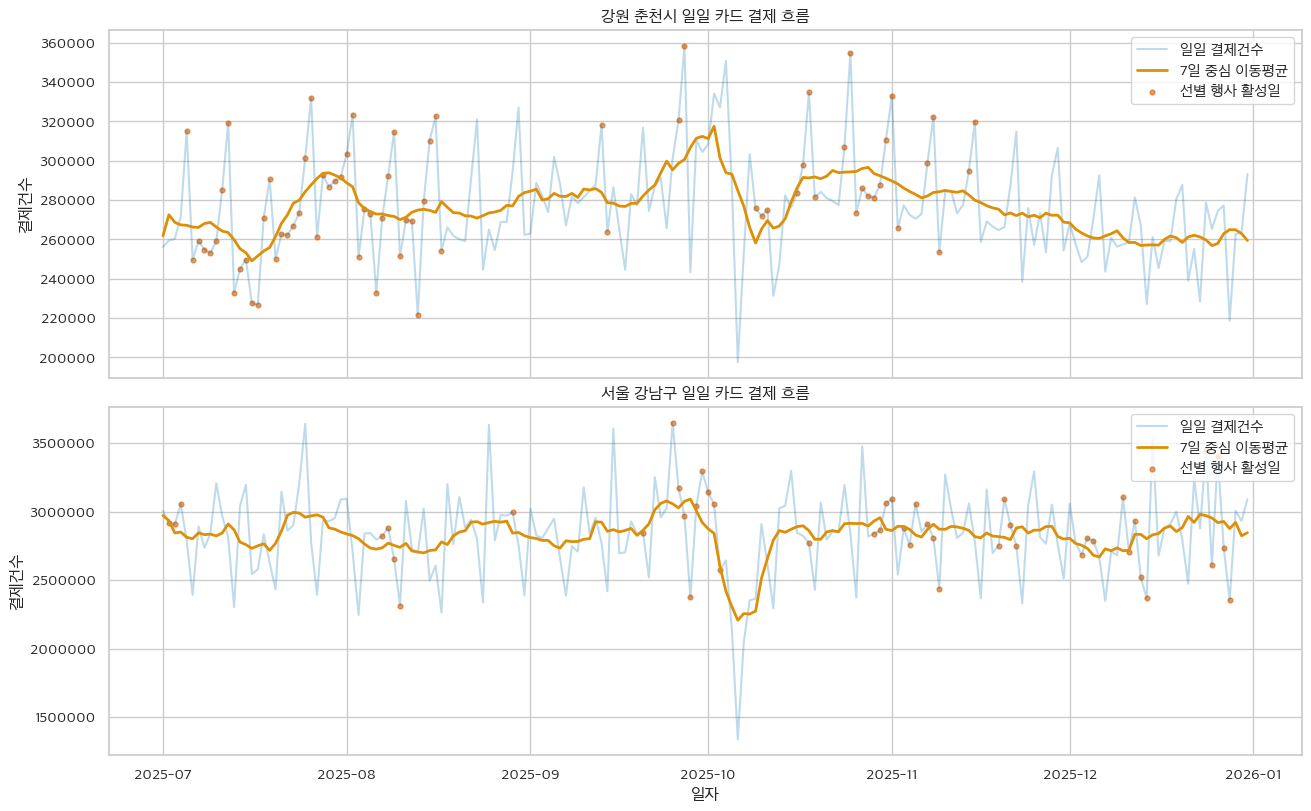

In [6]:
card_region_daily = analysis_daily.groupby(
    ["일자", "지역"], as_index=False, observed=True
).agg(
    결제건수=("결제건수", "sum"),
    결제금액=("결제금액", "sum"),
    행사수=("event_count", "max"),
)
card_region_daily["결제건수_7일평균"] = card_region_daily.groupby("지역")[
    "결제건수"
].transform(lambda values: values.rolling(7, center=True, min_periods=1).mean())

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, constrained_layout=True)
for ax, region in zip(axes, sorted(EXPECTED_REGIONS), strict=True):
    plot_data = card_region_daily[card_region_daily["지역"] == region]
    ax.plot(plot_data["일자"], plot_data["결제건수"], alpha=0.25, label="일일 결제건수")
    ax.plot(
        plot_data["일자"],
        plot_data["결제건수_7일평균"],
        linewidth=2,
        label="7일 중심 이동평균",
    )
    event_days = plot_data[plot_data["행사수"].gt(0)]
    ax.scatter(
        event_days["일자"],
        event_days["결제건수"],
        s=12,
        color="#D55E00",
        alpha=0.6,
        label="선별 행사 활성일",
    )
    ax.set(title=f"{region} 일일 카드 결제 흐름", ylabel="결제건수")
    ax.ticklabel_format(axis="y", style="plain")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("일자")
plt.show()

### 2. 전철 승하차 적재와 지역 필터 검증

In [7]:
gangnam_stations = {
    "삼성(무역센터)", "선릉", "역삼", "강남", "압구정", "신사", "매봉", "도곡",
    "대치", "학여울", "대청", "일원", "수서", "청담", "강남구청", "학동", "논현",
    "언주", "선정릉", "삼성중앙", "봉은사", "압구정로데오", "한티", "구룡", "개포동",
    "대모산입구",
}
chuncheon_stations = {"춘천", "남춘천", "김유정", "강촌", "백양리", "굴봉산"}

transport_parts = []
for transport_path in transport_files:
    transport_part = pd.read_csv(transport_path, encoding="utf-8-sig", index_col=False)
    transport_part["일자"] = pd.to_datetime(
        transport_part["사용일자"].astype(str), format="%Y%m%d"
    )
    transport_part["지역"] = np.select(
        [
            transport_part["역명"].isin(gangnam_stations),
            transport_part["역명"].isin(chuncheon_stations),
        ],
        ["서울 강남구", "강원 춘천시"],
        default="분석 제외",
    )
    transport_parts.append(transport_part[transport_part["지역"] != "분석 제외"])

transport = pd.concat(transport_parts, ignore_index=True)
transport["총승하차"] = transport["승차총승객수"] + transport["하차총승객수"]
transport_daily = transport.groupby(["일자", "지역"], as_index=False).agg(
    승차=("승차총승객수", "sum"),
    하차=("하차총승객수", "sum"),
    총승하차=("총승하차", "sum"),
    역명수=("역명", "nunique"),
)

assert set(transport_daily["지역"]) == EXPECTED_REGIONS
assert transport_daily.groupby("지역")["일자"].nunique().eq(len(EXPECTED_DATES)).all()
assert not transport_daily.duplicated(["일자", "지역"]).any()
assert transport_daily[["승차", "하차", "총승하차"]].ge(0).all().all()

transport_daily.groupby("지역", as_index=False).agg(
    관측일=("일자", "nunique"),
    최소역수=("역명수", "min"),
    최대역수=("역명수", "max"),
    총승하차=("총승하차", "sum"),
)

,지역,관측일,최소역수,최대역수,총승하차
0,강원 춘천시,184,6,6,2233527
1,서울 강남구,184,26,26,214884452


### 3. 카드·전철·SK 유동인구 월별 지수 비교

In [8]:
card_region_daily["기준월"] = card_region_daily["일자"].dt.strftime("%Y%m")
transport_daily["기준월"] = transport_daily["일자"].dt.strftime("%Y%m")

card_month = card_region_daily.groupby(["기준월", "지역"], as_index=False)["결제건수"].sum()
transport_month = transport_daily.groupby(["기준월", "지역"], as_index=False)["총승하차"].sum()
sk_month = (
    pd.read_csv(sk_segment_file, dtype={"기준월": "string"})
    .groupby(["기준월", "지역"], as_index=False)["일평균유동인구"]
    .sum()
)

monthly_comparison = (
    sk_month.merge(card_month, on=["기준월", "지역"], validate="one_to_one")
    .merge(transport_month, on=["기준월", "지역"], validate="one_to_one")
    .sort_values(["지역", "기준월"])
)
for metric in ["일평균유동인구", "결제건수", "총승하차"]:
    monthly_comparison[f"{metric}_7월100"] = 100 * monthly_comparison[metric] / monthly_comparison.groupby(
        "지역"
    )[metric].transform("first")

assert len(monthly_comparison) == 12
monthly_comparison.round(2)

,기준월,지역,일평균유동인구,결제건수,총승하차,일평균유동인구_7월100,결제건수_7월100,총승하차_7월100
0,202507,강원 춘천시,1796503.53,8358066,339829,100.00,100.00,100.00
2,202508,강원 춘천시,1860770.96,8561125,361725,103.58,102.43,106.44
4,202509,강원 춘천시,1954832.15,8591521,377637,108.81,102.79,111.13
6,202510,강원 춘천시,1889427.72,8923396,410227,105.17,106.76,120.72
8,202511,강원 춘천시,1861373.67,8380231,391402,103.61,100.27,115.18
10,202512,강원 춘천시,1774392.69,8090856,352707,98.77,96.80,103.79
1,202507,서울 강남구,7548745.41,88930496,37427341,100.00,100.00,100.00
3,202508,서울 강남구,7189803.87,86651159,34319182,95.25,97.44,91.70
5,202509,서울 강남구,7605416.75,87040423,36618882,100.75,97.87,97.84
7,202510,서울 강남구,7138284.90,84750452,32377657,94.56,95.30,86.51


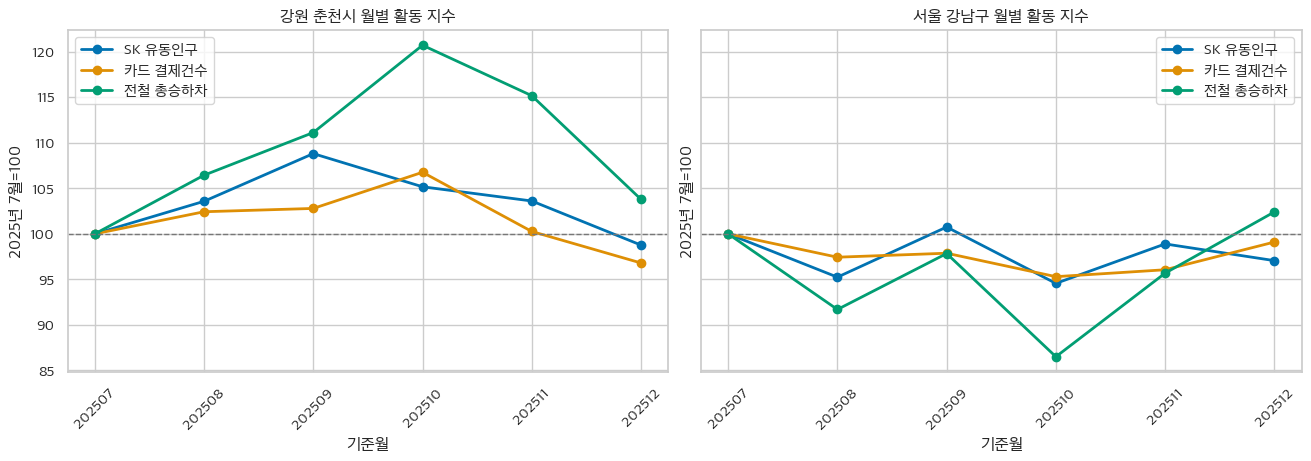

,일평균유동인구_7월대비(%),결제건수_7월대비(%),총승하차_7월대비(%)
지역,,,
강원 춘천시,-1.23,-3.2,3.79
서울 강남구,-2.94,-0.9,2.41


In [9]:
index_columns = [
    "일평균유동인구_7월100",
    "결제건수_7월100",
    "총승하차_7월100",
]
index_labels = {
    "일평균유동인구_7월100": "SK 유동인구",
    "결제건수_7월100": "카드 결제건수",
    "총승하차_7월100": "전철 총승하차",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
for ax, region in zip(axes, sorted(EXPECTED_REGIONS), strict=True):
    plot_data = monthly_comparison[monthly_comparison["지역"] == region]
    for column in index_columns:
        ax.plot(
            plot_data["기준월"],
            plot_data[column],
            marker="o",
            linewidth=2,
            label=index_labels[column],
        )
    ax.axhline(100, color="#777777", linestyle="--", linewidth=1)
    ax.set(title=f"{region} 월별 활동 지수", xlabel="기준월", ylabel="2025년 7월=100")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.show()

first_last = monthly_comparison[
    monthly_comparison["기준월"].isin(["202507", "202512"])
].pivot(index="지역", columns="기준월", values=["일평균유동인구", "결제건수", "총승하차"])
july_to_december = pd.DataFrame(
    {
        f"{metric}_7월대비(%)": 100
        * (first_last[(metric, "202512")] / first_last[(metric, "202507")] - 1)
        for metric in ["일평균유동인구", "결제건수", "총승하차"]
    }
)
july_to_december.round(2)

## Takeaways

1. **외부 데이터 결합 기반이 준비됐다.** 카드 일별 집계 4,416행에 지역·일자 기준으로 기상과 행사 달력을 손실 없이 결합했다.
2. **춘천의 기존 신호는 지역 전체 이동 감소와 동일하지 않다.** 7월 대비 12월 전체 유동인구와 카드 결제는 각각 1.23%, 3.20% 감소했지만 전철 총승하차는 3.79% 증가했다. 기존 EDA의 60대 이상 감소는 연령집단 특이 신호인지 우선 확인해야 한다.
3. **강남에서도 지표 방향이 갈렸다.** 전체 유동인구와 카드 결제는 각각 2.94%, 0.90% 감소했지만 전철 총승하차는 2.41% 증가했다. 한 종류의 활동 지표만으로 지역 활동을 판정하면 안 된다.
4. **일일 카드 흐름에는 강한 달력 변동이 보인다.** 요일·비근무일·날씨·행사가 겹치므로 행사 활성일의 단순 평균 차이를 행사 효과나 고립 신호로 해석하지 않는다.

### 다음 단계

- 성·연령 집단별 카드 결제에 요일·기상·공휴일·행사 변수를 반영한 해석 가능한 기준 모델을 만든다.
- 외부 요인 반영 전후의 월별 잔여 소비를 기존 고립 의심 신호와 비교한다.
- 전철은 지역 전체 이동량 보조 지표로만 사용하고 성·연령 집단 결과와 직접 연결하지 않는다.